# Unidad II - Actividad de Evaluacion 1
## Exploracion y diagnostico del conjunto de datos

**Alumno:** Mark Alan Moya Galindo  
**Proyecto:** Prediccion de demanda en un sistema de bicicletas compartidas  
**Dataset:** Bike Sharing - `hour.csv`  
**Fuente:** UCI Machine Learning Repository

> En esta actividad se trabaja directamente con `data/raw/hour.csv`. El archivo original no se elimina, limpia ni transforma.


## 1. Identificacion del dataset

El archivo `hour.csv` contiene registros horarios del sistema Capital Bikeshare para 2011 y 2012. Incluye informacion de calendario, clima y cantidad de usuarios. La fuente original tambien proporciona `day.csv`, pero para esta actividad el analisis principal se realiza sobre los datos horarios.


In [1]:
from pathlib import Path
import io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def localizar_hour_csv():
    rutas = [
        Path("data/raw/hour.csv"),
        Path("../data/raw/hour.csv"),
    ]
    for ruta in rutas:
        if ruta.exists():
            return ruta
    raise FileNotFoundError("No se encontro data/raw/hour.csv")

DATA_PATH = localizar_hour_csv()
df = pd.read_csv(DATA_PATH)

print("Archivo:", DATA_PATH)
print("Registros:", df.shape[0])
print("Variables:", df.shape[1])


Archivo: data/raw/hour.csv
Registros: 17379
Variables: 17


## 2. Carga y exploracion inicial

In [2]:
df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Interpretacion:** `df.head()` permite revisar las primeras filas y comprobar que el archivo fue cargado correctamente.

In [3]:
df.shape

(17379, 17)

**Interpretacion:** `df.shape` devuelve el numero de registros y variables. El archivo contiene 17,379 registros y 17 columnas.

In [4]:
df.columns.tolist()

['instant',
 'dteday',
 'season',
 'yr',
 'mnth',
 'hr',
 'holiday',
 'weekday',
 'workingday',
 'weathersit',
 'temp',
 'atemp',
 'hum',
 'windspeed',
 'casual',
 'registered',
 'cnt']

**Interpretacion:** `df.columns` muestra los nombres exactos de las variables disponibles.

In [5]:
buffer = io.StringIO()
df.info(buf=buffer)
print(buffer.getvalue())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB



**Interpretacion:** `df.info()` muestra tipos de datos, cantidad de valores no nulos y memoria utilizada. Todas las columnas tienen 17,379 valores no nulos.

In [6]:
df.dtypes

instant         int64
dteday         object
season          int64
yr              int64
mnth            int64
hr              int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
casual          int64
registered      int64
cnt             int64
dtype: object

**Interpretacion:** `df.dtypes` permite distinguir enteros, decimales y texto. `dteday` se mantiene como texto porque esta actividad es de diagnostico, no de transformacion.

In [7]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
instant,17379.0,NaN,NaN,NaN,8690.0,5017.0295,1.0,4345.5,8690.0,13034.5,17379.0
dteday,17379,731,2012-12-31,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
season,17379.0,NaN,NaN,NaN,2.50164,1.106918,1.0,2.0,3.0,3.0,4.0
yr,17379.0,NaN,NaN,NaN,0.502561,0.500008,0.0,0.0,1.0,1.0,1.0
mnth,17379.0,NaN,NaN,NaN,6.537775,3.438776,1.0,4.0,7.0,10.0,12.0
hr,17379.0,NaN,NaN,NaN,11.546752,6.914405,0.0,6.0,12.0,18.0,23.0
holiday,17379.0,NaN,NaN,NaN,0.02877,0.167165,0.0,0.0,0.0,0.0,1.0
weekday,17379.0,NaN,NaN,NaN,3.003683,2.005771,0.0,1.0,3.0,5.0,6.0
workingday,17379.0,NaN,NaN,NaN,0.682721,0.465431,0.0,0.0,1.0,1.0,1.0
weathersit,17379.0,NaN,NaN,NaN,1.425283,0.639357,1.0,1.0,1.0,2.0,4.0


**Interpretacion:** `df.describe()` resume medidas de tendencia central, dispersion, minimos, maximos y cuartiles de las variables numericas.

## 3. Diccionario de datos

In [8]:
diccionario = pd.DataFrame([['instant', 'Indice del registro', 'int64', 'Cuantitativa', 'Discreta', 'Registro', 'Identificacion; no se propone como predictor'], ['dteday', 'Fecha de observacion', 'object', 'Cualitativa/temporal', 'Temporal', 'Fecha', 'Analisis de tendencias por fecha'], ['season', 'Temporada (1-4)', 'int64', 'Cualitativa', 'Nominal codificada', 'Categoria', 'Comparar demanda por temporada'], ['yr', 'Anio (0=2011, 1=2012)', 'int64', 'Cualitativa', 'Binaria', 'Categoria', 'Comparar los dos anios'], ['mnth', 'Mes (1-12)', 'int64', 'Cualitativa', 'Ordinal', 'Mes', 'Patrones mensuales'], ['hr', 'Hora (0-23)', 'int64', 'Cualitativa', 'Ordinal', 'Hora', 'Patrones horarios y predictor'], ['holiday', 'Indica dia festivo', 'int64', 'Cualitativa', 'Binaria', 'Categoria', 'Efecto de dias festivos'], ['weekday', 'Dia de la semana (0-6)', 'int64', 'Cualitativa', 'Nominal codificada', 'Categoria', 'Patrones semanales'], ['workingday', 'Dia laborable', 'int64', 'Cualitativa', 'Binaria', 'Categoria', 'Comparar dias laborables/no laborables'], ['weathersit', 'Situacion climatica (1-4)', 'int64', 'Cualitativa', 'Ordinal', 'Categoria', 'Relacion entre clima y demanda'], ['temp', 'Temperatura normalizada', 'float64', 'Cuantitativa', 'Continua', 'Proporcion normalizada', 'Predictor meteorologico'], ['atemp', 'Sensacion termica normalizada', 'float64', 'Cuantitativa', 'Continua', 'Proporcion normalizada', 'Predictor meteorologico'], ['hum', 'Humedad normalizada', 'float64', 'Cuantitativa', 'Continua', 'Proporcion normalizada', 'Predictor meteorologico'], ['windspeed', 'Velocidad del viento normalizada', 'float64', 'Cuantitativa', 'Continua', 'Proporcion normalizada', 'Predictor meteorologico'], ['casual', 'Usuarios casuales', 'int64', 'Cuantitativa', 'Discreta', 'Usuarios', 'Descripcion de demanda; evitar como predictor directo de cnt'], ['registered', 'Usuarios registrados', 'int64', 'Cuantitativa', 'Discreta', 'Usuarios', 'Descripcion de demanda; evitar como predictor directo de cnt'], ['cnt', 'Total de bicicletas rentadas', 'int64', 'Cuantitativa', 'Discreta', 'Rentas', 'Variable objetivo propuesta para regresion']], columns=[
"Variable","Descripcion","Tipo Python","Tipo de variable","Clasificacion","Unidad de medida","Posible utilidad"
])
diccionario

,Variable,Descripcion,Tipo Python,Tipo de variable,Clasificacion,Unidad de medida,Posible utilidad
0,instant,Indice del registro,int64,Cuantitativa,Discreta,Registro,Identificacion; no se propone como predictor
1,dteday,Fecha de observacion,object,Cualitativa/temporal,Temporal,Fecha,Analisis de tendencias por fecha
2,season,Temporada (1-4),int64,Cualitativa,Nominal codificada,Categoria,Comparar demanda por temporada
3,yr,"Anio (0=2011, 1=2012)",int64,Cualitativa,Binaria,Categoria,Comparar los dos anios
4,mnth,Mes (1-12),int64,Cualitativa,Ordinal,Mes,Patrones mensuales
5,hr,Hora (0-23),int64,Cualitativa,Ordinal,Hora,Patrones horarios y predictor
6,holiday,Indica dia festivo,int64,Cualitativa,Binaria,Categoria,Efecto de dias festivos
7,weekday,Dia de la semana (0-6),int64,Cualitativa,Nominal codificada,Categoria,Patrones semanales
8,workingday,Dia laborable,int64,Cualitativa,Binaria,Categoria,Comparar dias laborables/no laborables
9,weathersit,Situacion climatica (1-4),int64,Cualitativa,Ordinal,Categoria,Relacion entre clima y demanda


## 4. Tipo y fuente de los datos

Los datos son **estructurados**, porque se almacenan en un archivo CSV con filas y columnas. La informacion combina dos fuentes principales:

- **Datos transaccionales/operacionales:** conteos de rentas del sistema de bicicletas.
- **Datos ambientales/meteorologicos:** temperatura, humedad, viento y situacion climatica agregados al dataset.

Los registros representan observaciones reales del sistema de bicicletas y su contexto temporal y climatico.


## 5. Diagnostico de calidad

### 5.1 Valores faltantes

In [9]:
faltantes = df.isnull().sum().to_frame("faltantes")
faltantes["porcentaje"] = (faltantes["faltantes"] / len(df) * 100).round(2)
faltantes

,faltantes,porcentaje
instant,0,0.0
dteday,0,0.0
season,0,0.0
yr,0,0.0
mnth,0,0.0
hr,0,0.0
holiday,0,0.0
weekday,0,0.0
workingday,0,0.0
weathersit,0,0.0


**Interpretacion:** no se detectan valores faltantes. Por lo tanto, no se propone imputacion en esta etapa. Si aparecieran en una fuente futura, su tratamiento dependeria de la variable y del porcentaje afectado.

### 5.2 Registros duplicados

In [10]:
duplicados = int(df.duplicated().sum())
print("Registros duplicados:", duplicados)

Registros duplicados: 0


**Interpretacion:** no existen filas completas duplicadas. Si aparecieran duplicados, una causa posible seria una doble carga del mismo registro y se revisarian las claves temporales antes de eliminarlos.

### 5.3 Valores incorrectos o inconsistentes

In [11]:
comprobaciones = pd.Series({
    "season entre 1 y 4": df["season"].between(1,4).all(),
    "yr entre 0 y 1": df["yr"].between(0,1).all(),
    "mnth entre 1 y 12": df["mnth"].between(1,12).all(),
    "hr entre 0 y 23": df["hr"].between(0,23).all(),
    "holiday entre 0 y 1": df["holiday"].between(0,1).all(),
    "weekday entre 0 y 6": df["weekday"].between(0,6).all(),
    "workingday entre 0 y 1": df["workingday"].between(0,1).all(),
    "weathersit entre 1 y 4": df["weathersit"].between(1,4).all(),
    "temp entre 0 y 1": df["temp"].between(0,1).all(),
    "atemp entre 0 y 1": df["atemp"].between(0,1).all(),
    "hum entre 0 y 1": df["hum"].between(0,1).all(),
    "windspeed entre 0 y 1": df["windspeed"].between(0,1).all(),
    "conteos no negativos": (df[["casual","registered","cnt"]] >= 0).all().all(),
    "cnt = casual + registered": (df["cnt"] == df["casual"] + df["registered"]).all(),
})
comprobaciones.to_frame("cumple")

,cumple
season entre 1 y 4,True
yr entre 0 y 1,True
mnth entre 1 y 12,True
hr entre 0 y 23,True
holiday entre 0 y 1,True
weekday entre 0 y 6,True
workingday entre 0 y 1,True
weathersit entre 1 y 4,True
temp entre 0 y 1,True
atemp entre 0 y 1,True


**Interpretacion:** las reglas de rango y la relacion `cnt = casual + registered` son coherentes en el archivo revisado. No se detectan inconsistencias evidentes que obliguen a corregir el dataset en esta etapa.

## 6. Analisis estadistico inicial

In [12]:
variables = ["cnt","temp","hum"]
estadisticas = pd.DataFrame({
    "Media": df[variables].mean(),
    "Mediana": df[variables].median(),
    "Minimo": df[variables].min(),
    "Maximo": df[variables].max(),
    "Desviacion estandar": df[variables].std()
})
estadisticas.round(4)

,Media,Mediana,Minimo,Maximo,Desviacion estandar
cnt,189.4631,142.00,1.00,977.0,181.3876
temp,0.4970,0.50,0.02,1.0,0.1926
hum,0.6272,0.63,0.00,1.0,0.1929


**Interpretacion:** `cnt` presenta una media cercana a 189.46 rentas por hora y una desviacion estandar cercana a 181.39, lo que indica alta variacion en la demanda. `temp` y `hum` estan normalizadas entre 0 y 1, por lo que deben interpretarse como proporciones respecto a sus valores maximos definidos por el dataset.


## 7. Deteccion inicial de valores atipicos

In [13]:
def resumen_iqr(serie):
    q1 = serie.quantile(.25)
    q3 = serie.quantile(.75)
    iqr = q3 - q1
    li = q1 - 1.5 * iqr
    ls = q3 + 1.5 * iqr
    n = int(((serie < li) | (serie > ls)).sum())
    return pd.Series({
        "Q1": q1, "Q3": q3, "IQR": iqr,
        "Limite inferior": li, "Limite superior": ls,
        "Posibles atipicos": n
    })

pd.DataFrame({v: resumen_iqr(df[v]) for v in ["cnt","temp","hum","windspeed"]}).T.round(4)

,Q1,Q3,IQR,Limite inferior,Limite superior,Posibles atipicos
cnt,40.0000,281.0000,241.0000,-321.5000,642.5000,505.0
temp,0.3400,0.6600,0.3200,-0.1400,1.1400,0.0
hum,0.4800,0.7800,0.3000,0.0300,1.2300,22.0
windspeed,0.1045,0.2537,0.1492,-0.1193,0.4775,342.0


**Interpretacion:** por IQR se detectan 505 posibles atipicos en `cnt`, 22 en `hum` y 342 en `windspeed`; `temp` no presenta valores atipicos bajo este criterio. Estos puntos no se eliminan, porque pueden representar condiciones reales, por ejemplo horas de demanda excepcionalmente alta o registros meteorologicos extremos.


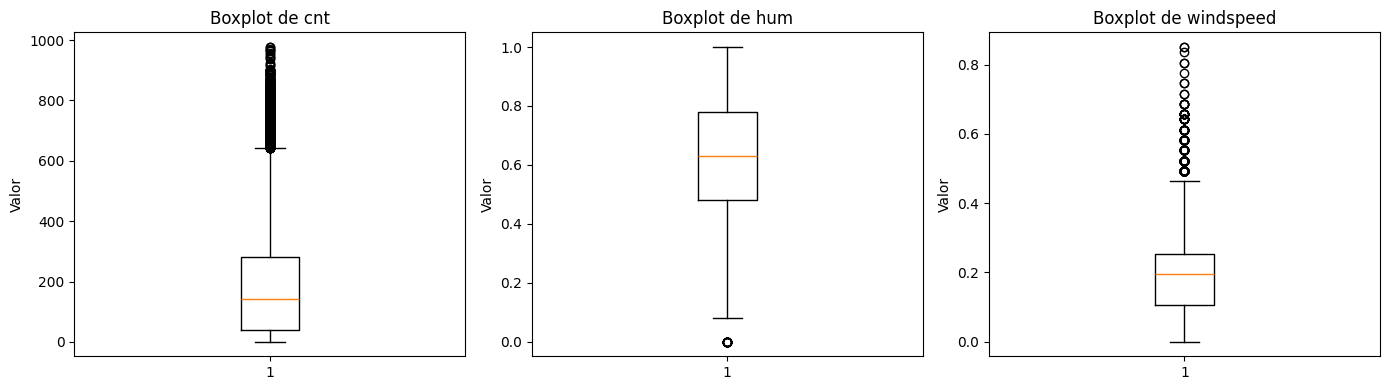

In [14]:
fig, axes = plt.subplots(1,3,figsize=(14,4))
for ax, col in zip(axes, ["cnt","hum","windspeed"]):
    ax.boxplot(df[col].dropna())
    ax.set_title(f"Boxplot de {col}")
    ax.set_ylabel("Valor")
plt.tight_layout()
plt.show()

## 8. Visualizacion inicial

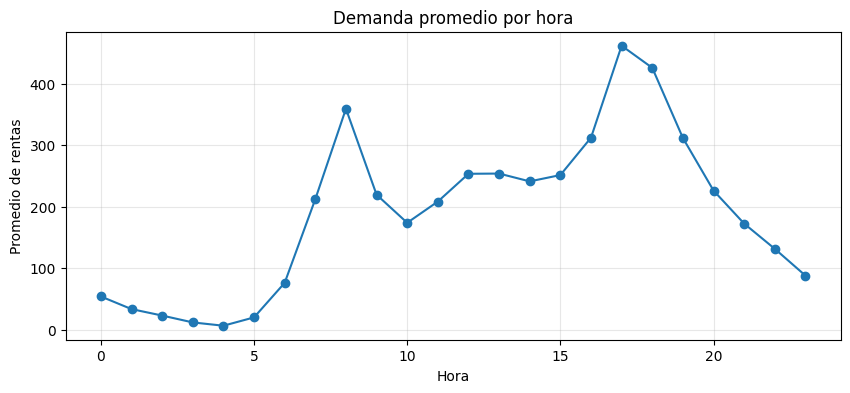

In [15]:
demanda_hora = df.groupby("hr")["cnt"].mean()
plt.figure(figsize=(10,4))
plt.plot(demanda_hora.index, demanda_hora.values, marker="o")
plt.title("Demanda promedio por hora")
plt.xlabel("Hora")
plt.ylabel("Promedio de rentas")
plt.grid(alpha=.3)
plt.show()

**Interpretacion:** la demanda es muy baja durante la madrugada y presenta picos importantes alrededor de las 08:00 y, especialmente, de las 17:00 a 18:00. Esto sugiere un patron asociado a horarios de traslado.

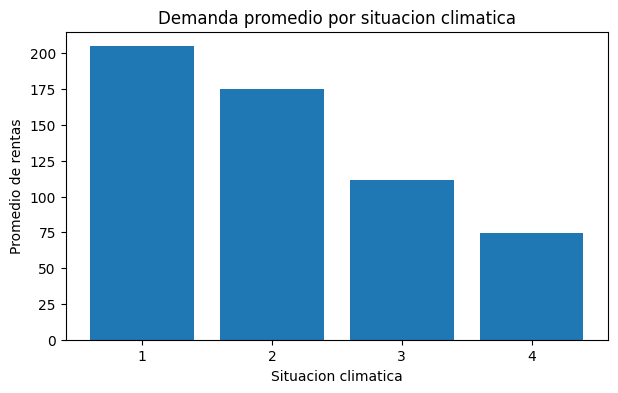

In [16]:
demanda_clima = df.groupby("weathersit")["cnt"].mean()
plt.figure(figsize=(7,4))
plt.bar(demanda_clima.index.astype(str), demanda_clima.values)
plt.title("Demanda promedio por situacion climatica")
plt.xlabel("Situacion climatica")
plt.ylabel("Promedio de rentas")
plt.show()

**Interpretacion:** la demanda promedio disminuye conforme la condicion climatica es mas adversa. Esto respalda el uso de `weathersit` como variable explicativa.

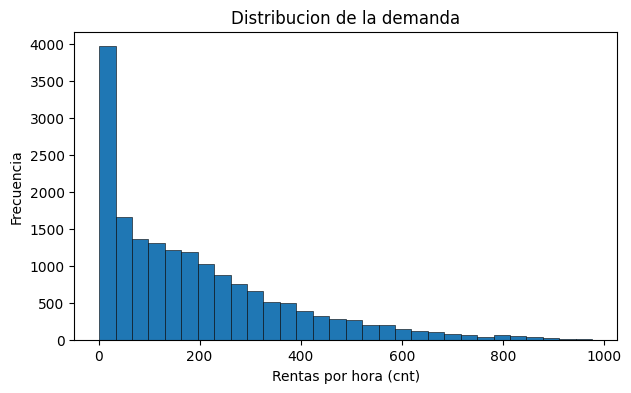

In [17]:
plt.figure(figsize=(7,4))
plt.hist(df["cnt"], bins=30, edgecolor="black", linewidth=.4)
plt.title("Distribucion de la demanda")
plt.xlabel("Rentas por hora (cnt)")
plt.ylabel("Frecuencia")
plt.show()

**Interpretacion:** la distribucion de `cnt` esta sesgada hacia valores altos; hay muchas horas con demanda baja o media y un grupo menor con demanda elevada.

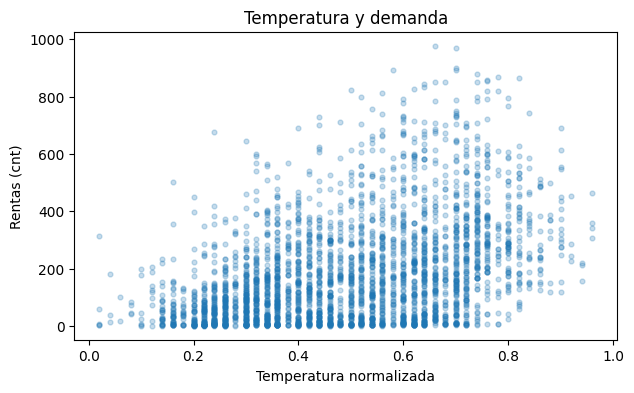

In [18]:
muestra = df.sample(min(3000, len(df)), random_state=42)
plt.figure(figsize=(7,4))
plt.scatter(muestra["temp"], muestra["cnt"], alpha=.25, s=12)
plt.title("Temperatura y demanda")
plt.xlabel("Temperatura normalizada")
plt.ylabel("Rentas (cnt)")
plt.show()

**Interpretacion:** se observa una tendencia general de mayor demanda en temperaturas medias y altas, aunque la relacion no es suficiente por si sola para explicar el comportamiento; tambien influyen la hora, el dia y el clima.

## 9. Preparacion para analisis posteriores

### Regresion
- **Objetivo:** `cnt`.
- **Proposito:** predecir el total de bicicletas rentadas por hora.
- **Entradas propuestas:** `hr`, `weekday`, `workingday`, `holiday`, `season`, `mnth`, `yr`, `weathersit`, `temp`, `atemp`, `hum`, `windspeed`.
- `casual` y `registered` no se usaran como predictores directos de `cnt` porque su suma define el valor de `cnt`.

### Clasificacion
- **Objetivo propuesto:** nivel de demanda.
- **Clases:** baja, media y alta.
- Los puntos de corte se definiran y documentaran en la etapa de modelado, utilizando un criterio reproducible como cuantiles del conjunto de entrenamiento.

### Agrupamiento
- **Variables sugeridas:** `hr`, `weekday`, `season`, `weathersit`, `temp`, `hum`, `windspeed`, `cnt`.
- **Proposito:** descubrir perfiles de uso que relacionen horarios, clima, temporada y volumen de demanda.


## 10. Conclusion del diagnostico

1. **¿Que informacion contiene el dataset?** Registros horarios de uso de bicicletas, calendario y condiciones meteorologicas.
2. **¿Cual es su nivel general de calidad?** Bueno para continuar con el analisis: no presenta faltantes ni filas duplicadas.
3. **¿Que problemas fueron identificados?** Principalmente posibles valores atipicos por criterio IQR.
4. **¿Que variables requieren tratamiento?** `cnt`, `hum` y `windspeed` requieren revision de valores extremos; `dteday` podra transformarse a tipo fecha posteriormente.
5. **¿Existen valores faltantes?** No.
6. **¿Existen registros duplicados?** No.
7. **¿Existen valores atipicos?** Si: el diagnostico IQR identifica posibles extremos, pero no se eliminan en esta etapa.
8. **¿Que transformaciones seran necesarias?** Conversion de fecha, posible codificacion/ingenieria de variables y tratamiento justificado de extremos solo si el modelado lo requiere.
9. **¿Los datos son adecuados para continuar?** Si.
10. **¿Que conocimiento puede obtenerse?** Patrones de demanda por horario, clima, temporada y tipo de dia, asi como modelos para predecir o clasificar niveles de demanda.
